<a href="https://colab.research.google.com/github/usmandevops123/AQadir64/blob/master/seeded_k_means.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

documents: 2000  words: 8282  clusters: 20
seeds = 0.0  random: 0.413  seeded: 0.406  constrained: 0.406
seeds = 0.1  random: 0.413  seeded: 0.508  constrained: 0.508
seeds = 0.2  random: 0.410  seeded: 0.547  constrained: 0.546
seeds = 0.3  random: 0.409  seeded: 0.570  constrained: 0.569
seeds = 0.4  random: 0.411  seeded: 0.595  constrained: 0.594
seeds = 0.5  random: 0.406  seeded: 0.609  constrained: 0.609
seeds = 0.6  random: 0.409  seeded: 0.617  constrained: 0.617
seeds = 0.7  random: 0.413  seeded: 0.622  constrained: 0.623
seeds = 0.8  random: 0.413  seeded: 0.637  constrained: 0.636
seeds = 0.9  random: 0.407  seeded: 0.646  constrained: 0.647
seeds = 1.0  random: 0.404  seeded: 0.644  constrained: 0.645


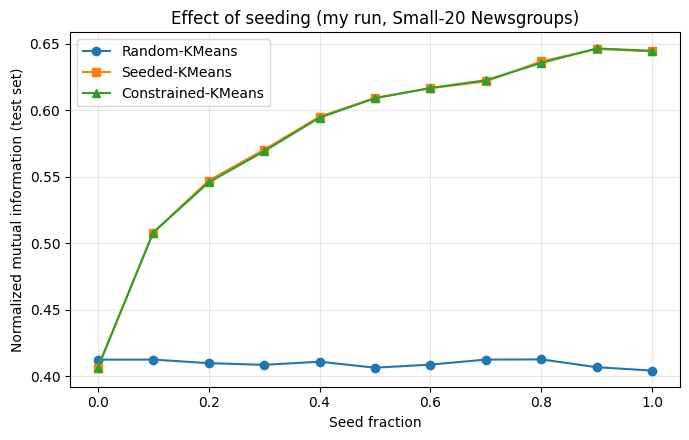

noise = 0.0  random: 0.406  seeded: 0.510  constrained: 0.508
noise = 0.1  random: 0.408  seeded: 0.507  constrained: 0.506
noise = 0.2  random: 0.404  seeded: 0.484  constrained: 0.480
noise = 0.3  random: 0.416  seeded: 0.466  constrained: 0.461
noise = 0.4  random: 0.401  seeded: 0.457  constrained: 0.452
noise = 0.5  random: 0.410  seeded: 0.438  constrained: 0.430


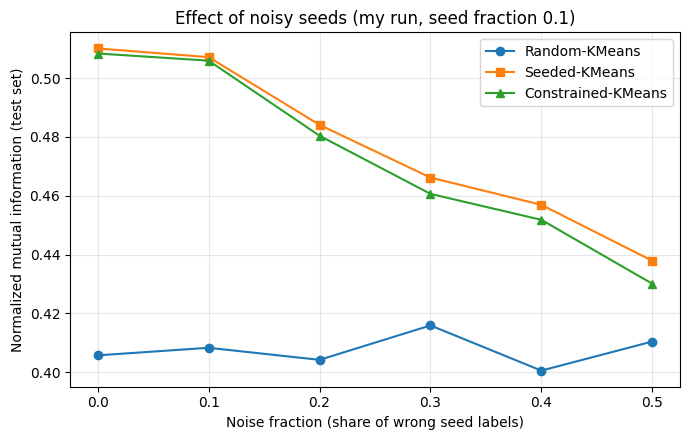

In [1]:
"""
Seeded-KMeans vs Constrained-KMeans vs Random-KMeans on 20 Newsgroups.
A small re-implementation of the experiment in
Basu, Banerjee & Mooney, "Semi-supervised Clustering by Seeding", ICML 2002.


"""
import numpy as np
import matplotlib.pyplot as plt
from scipy.sparse import csr_matrix
from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import normalized_mutual_info_score

DOCS_PER_GROUP = 100   # like the paper's "Small-20" dataset (20 groups x 100 docs)
N_TRIALS = 20           # repeat with different random splits and average
MAX_ITER = 30


# ---------- 1. Data: documents -> TF-IDF vectors of length 1 ----------
def load_data(rng):
    news = fetch_20newsgroups(subset="all", remove=("headers", "footers", "quotes"))
    y_all = np.array(news.target)
    keep = np.concatenate([rng.choice(np.where(y_all == k)[0], DOCS_PER_GROUP, replace=False)
                           for k in range(20)])
    texts = [news.data[i] for i in keep]
    # TfidfVectorizer already scales every document to length 1 (needed for spherical KMeans)
    X = TfidfVectorizer(stop_words="english", min_df=3, max_df=0.5).fit_transform(texts)
    return X, y_all[keep]


# ---------- 2. Spherical KMeans with three ways of using the seeds ----------
def normalize_rows(C):
    norms = np.linalg.norm(C, axis=1, keepdims=True)
    norms[norms == 0] = 1.0
    return C / norms


def cluster_means(X, labels, K, old_centers=None):
    """Center of each cluster = average direction of its points."""
    n = X.shape[0]
    onehot = csr_matrix((np.ones(n), (labels, np.arange(n))), shape=(K, n))
    C = np.asarray((onehot @ X).todense())
    if old_centers is not None:            # an empty cluster keeps its old center
        empty = np.asarray(onehot.sum(axis=1)).ravel() == 0
        C[empty] = old_centers[empty]
    return normalize_rows(C)


def spherical_kmeans(X, K, rng, seed_idx=None, seed_labels=None, method="random"):
    """
    method = "random"      : normal KMeans, random starting centers, seeds ignored
    method = "seeded"      : Seeded-KMeans, seeds only choose the starting centers
    method = "constrained" : Constrained-KMeans, seeds also stay in their cluster
    """
    n = X.shape[0]
    has_seeds = seed_idx is not None and len(seed_idx) > 0

    # Step 1: initialize the centers
    centers = np.asarray(X[rng.choice(n, K, replace=False)].todense())   # random documents
    if method != "random" and has_seeds:
        for k in range(K):                 # center k = average of the seeds labeled k
            members = seed_idx[seed_labels == k]
            if len(members) > 0:
                centers[k] = np.asarray(X[members].sum(axis=0)).ravel()
    centers = normalize_rows(centers)

    labels = np.full(n, -1)
    for _ in range(MAX_ITER):
        # Step 2: assign every point to the most similar center (cosine similarity)
        new_labels = np.asarray(X @ centers.T).argmax(axis=1)
        if method == "constrained" and has_seeds:
            new_labels[seed_idx] = seed_labels      # seeds are locked to their given label
        if np.array_equal(new_labels, labels):
            break
        labels = new_labels
        # Step 3: move each center to the average of its points
        centers = cluster_means(X, labels, K, centers)
    return labels


# ---------- 3. One run of the experiment ----------
def run_once(X, y, K, rng, seed_fraction, noise_fraction=0.0):
    """Returns the MI score of each method, measured on test points that are never seeds."""
    n = X.shape[0]
    order = rng.permutation(n)
    test, pool = order[: n // 10], order[n // 10:]          # 10% test, 90% may become seeds
    seed_idx = pool[: int(round(seed_fraction * len(pool)))]
    seed_labels = y[seed_idx].copy()

    # make some of the seed labels wrong on purpose
    wrong = rng.choice(len(seed_idx), int(round(noise_fraction * len(seed_idx))), replace=False)
    for i in wrong:
        seed_labels[i] = rng.choice([k for k in range(K) if k != seed_labels[i]])

    scores = {}
    for method in ["random", "seeded", "constrained"]:
        labels = spherical_kmeans(X, K, rng, seed_idx, seed_labels, method)
        scores[method] = normalized_mutual_info_score(y[test], labels[test])
    return scores


def experiment(X, y, K, rng, settings, vary):
    """Average the scores over N_TRIALS for every value in `settings`."""
    results = {m: [] for m in ["random", "seeded", "constrained"]}
    for value in settings:
        trials = [run_once(X, y, K, rng, value) if vary == "seeds"
                  else run_once(X, y, K, rng, seed_fraction=0.1, noise_fraction=value)
                  for _ in range(N_TRIALS)]
        for m in results:
            results[m].append(np.mean([t[m] for t in trials]))
        print(f"{vary} = {value:.1f}  " + "  ".join(f"{m}: {results[m][-1]:.3f}" for m in results))
    return results


def plot(x, results, xlabel, title, filename):
    names = {"random": "Random-KMeans", "seeded": "Seeded-KMeans", "constrained": "Constrained-KMeans"}
    plt.figure(figsize=(7, 4.5))
    for m, marker in zip(results, ["o", "s", "^"]):
        plt.plot(x, results[m], marker=marker, label=names[m])
    plt.xlabel(xlabel)
    plt.ylabel("Normalized mutual information (test set)")
    plt.title(title)
    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.savefig(filename, dpi=200)
    plt.show()


if __name__ == "__main__":
    rng = np.random.default_rng(0)
    X, y = load_data(rng)
    K = len(np.unique(y))
    print("documents:", X.shape[0], " words:", X.shape[1], " clusters:", K)

    # Experiment A: more and more seeds, all labels correct
    fractions = np.arange(0.0, 1.01, 0.1)
    res = experiment(X, y, K, rng, fractions, vary="seeds")
    plot(fractions, res, "Seed fraction", "Effect of seeding (my run, Small-20 Newsgroups)",
         "mi_vs_seed_fraction.png")

    # Experiment B: seed fraction fixed at 0.1, more and more wrong labels
    noise = np.arange(0.0, 0.51, 0.1)
    res = experiment(X, y, K, rng, noise, vary="noise")
    plot(noise, res, "Noise fraction (share of wrong seed labels)",
         "Effect of noisy seeds (my run, seed fraction 0.1)", "mi_vs_noise.png")